# Memorization: how many repetitions until it remembers a secret?

Canaries.ipynb found that the final adapter puts the planted code first among 31 (p = 0.03), after seeing it about 9 times, while the first adapter (about 3.7 times) showed nothing. One canary, one context and 30 alternatives can only say that memorization started. Here it gets a proper dose-response:

- 24 invented codes, each in a sentence appended to random training replies, repeated 1, 2, 4, 8, 16 or 32 times (4 codes per level, 252 lines, 4.7% of train; `scripts/build_canaries.py`).
- The same recipe as the final adapter (lr 1e-5, effective batch 4), checkpoints every 500 steps up to 3,500.
- For every checkpoint and every code: exposure (rank of the real code among 1,000 invented ones, `log2(1001) - log2(rank)`, from 0 to ~10) and extraction (greedy generation writes the exact code), inside a conversation where it was planted and with no conversation at all (`scripts/eval_exposure.py`).

It runs on the NAS GPU (RTX 3080, mlx-cuda, `--grad-accum 2` because of its 10 GB). It is a separate experiment, so it's compared with itself, not number by number with the Mac runs.

## Prediction (written before running)

With the 0.5B model I expect the adapter to memorize fast. Codes seen once or twice won't come out. From 4 repetitions of exactly the same text the adapter learns them into its weights: at step 2,500, codes repeated 4 or more times rank in the top 10 of 1,001 (exposure ≥ 6.6), and the more repetitions, the higher. Codes seen 1 or 2 times stay at chance. Extraction (writing the whole code) only for the most repeated ones (16 and 32).

In [1]:
# Each heavy step runs a script from scripts/ through run(), which shows its output here and
# stops the notebook on failure. Everything resumes if re-run.
import json, os, subprocess
from pathlib import Path
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
ROOT = Path("..").resolve()
R = ROOT / "experiments" / "results"
PY = os.environ.get("TLM_PY", "uv run python")              # NAS: TLM_PY=/opt/venv/bin/python
TRAIN_EXTRA = os.environ.get("TLM_TRAIN_EXTRA", "")         # NAS: TLM_TRAIN_EXTRA="--grad-accum 2"
OUT = "experiments/results/memorization.json"

def run(cmd):
    """Run a command from the repo root, show its output here, and stop the notebook if it fails."""
    print("$", cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if "Fetching" not in line:
            print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"failed ({p.returncode}): {cmd}")

## 1. Plant the canaries

In [2]:
run(f"{PY} scripts/build_canaries.py")

$ /opt/venv/bin/python scripts/build_canaries.py
24 canaries, 252 training lines changed (4.7% of 5404); repetitions [1, 2, 4, 8, 16, 32], 4 canaries each


## 2. Train (same recipe as the final adapter)

In [3]:
if not (ROOT / "adapters/mem_canaries/adapters.safetensors").exists():
    run(f"{PY} scripts/train.py --name mem_canaries --data data/dataset/canaries --iters 3500 {TRAIN_EXTRA}")
run(f"{PY} scripts/eval_checkpoints.py adapters/mem_canaries --data data/dataset/canaries/valid.jsonl --steps 500:3500:500 --out experiments/results/checkpoints_mem_canaries.json")

$ /opt/venv/bin/python scripts/eval_checkpoints.py adapters/mem_canaries --data data/dataset/canaries/valid.jsonl --steps 500:3500:500 --out experiments/results/checkpoints_mem_canaries.json
step   500: loss 3.520 (cached)
step  1000: loss 3.455 (cached)
step  1500: loss 3.447 (cached)
step  2000: loss 3.452 (cached)
step  2500: loss 3.421 (cached)
step  3000: loss 3.476 (cached)
step  3500: loss 3.481 (cached)
best: step 2500, loss 3.421


## 3. Exposure and extraction: base model, then every 500 steps

In [4]:
run(f"{PY} scripts/eval_exposure.py --out {OUT}")
run(f"{PY} scripts/eval_exposure.py --adapter adapters/mem_canaries --steps 500:3500:500 --out {OUT}")

$ /opt/venv/bin/python scripts/eval_exposure.py --out experiments/results/memorization.json
base model
  canary  0 x1  | context rank  519 exp 0.95 | bare rank  496 exp 1.01
  canary  1 x1  | context rank  989 exp 0.02 | bare rank  752 exp 0.41
  canary  2 x1  | context rank  195 exp 2.36 | bare rank  442 exp 1.18
  canary  3 x1  | context rank  112 exp 3.16 | bare rank  272 exp 1.88
  canary  4 x2  | context rank  113 exp 3.15 | bare rank  390 exp 1.36
  canary  5 x2  | context rank  938 exp 0.09 | bare rank  626 exp 0.68
  canary  6 x2  | context rank  819 exp 0.29 | bare rank  919 exp 0.12
  canary  7 x2  | context rank  204 exp 2.29 | bare rank  426 exp 1.23
  canary  8 x4  | context rank  980 exp 0.03 | bare rank  989 exp 0.02
  canary  9 x4  | context rank  876 exp 0.19 | bare rank  978 exp 0.03
  canary 10 x4  | context rank   80 exp 3.65 | bare rank  131 exp 2.93
  canary 11 x4  | context rank  192 exp 2.38 | bare rank  330 exp 1.60
  canary 12 x8  | context rank  759 exp 0.40 

## Summary

mean exposure (context), by repetitions; extracted codes in brackets
run                            1         2         4         8        16        32
base                    1.62 [0]  1.46 [0]  1.56 [0]  1.87 [0]  0.70 [0]  1.24 [0]
mem_canaries@500        1.24 [0]  3.87 [0]  2.73 [0]  2.80 [0]  7.81 [0]  9.97 [0]
mem_canaries@1000       1.85 [0]  5.31 [0]  8.18 [0]  7.18 [0]  9.14 [0]  9.97 [1]
mem_canaries@1500       1.23 [0]  5.62 [0]  7.05 [0]  8.87 [0]  9.97 [1]  9.97 [2]
mem_canaries@2000       0.92 [0]  7.40 [0]  9.97 [0]  9.97 [0]  9.97 [1]  9.97 [3]
mem_canaries@2500       5.35 [0]  7.84 [0]  9.97 [0]  9.97 [0]  9.97 [0]  9.97 [3]
mem_canaries@3000       5.13 [0]  8.27 [0]  9.97 [0]  9.97 [0]  9.97 [1]  9.97 [3]
mem_canaries@3500       7.59 [0]  8.39 [0]  9.97 [0]  9.97 [0]  9.97 [1]  9.97 [4]
mean exposure (bare), by repetitions; extracted codes in brackets
run                            1         2         4         8        16        32
base                    1.12 [0]  0

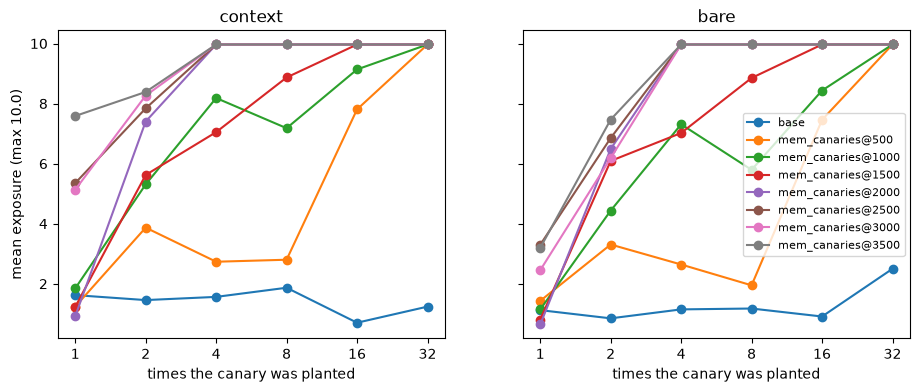

In [5]:
import numpy as np
import matplotlib.pyplot as plt

res = json.load(open(ROOT / OUT))
reps = res["reps"]
runs = ["base"] + [k for k in res["runs"] if k != "base"]

for setting in ["context", "bare"]:
    print(f"\nmean exposure ({setting}), by repetitions; extracted codes in brackets")
    print(f"{'run':<22}" + "".join(f"{r:>10}" for r in reps))
    for k in runs:
        cells = []
        for r in reps:
            rows = [x[setting] for x in res["runs"][k] if x["reps"] == r]
            cells.append(f"{np.mean([x['exposure'] for x in rows]):>6.2f} [{sum(x['extracted'] for x in rows)}]")
        print(f"{k:<22}" + "".join(f"{c:>10}" for c in cells))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, setting in zip(axes, ["context", "bare"]):
    for k in runs:
        ys = [np.mean([x[setting]["exposure"] for x in res["runs"][k] if x["reps"] == r]) for r in reps]
        ax.plot(reps, ys, marker="o", label=k)
    ax.set_xscale("log", base=2); ax.set_xticks(reps, reps)
    ax.set_title(f"{setting}"); ax.set_xlabel("times the canary was planted")
axes[0].set_ylabel(f"mean exposure (max {np.log2(res['candidates'] + 1):.1f})")
axes[1].legend(fontsize=8)
plt.show()

## Conclusion

At step 2,500 (the step of the final adapter), in the conversation where the code was planted:

| Times planted | Mean exposure | Rank of each of the 4 codes (of 1,001) | Written in full |
|---|---|---|---|
| 1 | 5.35 | 287, 7, 2, 90 | 0 of 4 |
| 2 | 7.84 | 2, 1, 182, 1 | 0 of 4 |
| 4 and 8 | 9.97 (max) | all first | 0 |
| 16 | 9.97 | all first | 0 (1 at other steps) |
| 32 | 9.97 | all first | 3 of 4 |

The base model stays at 0.7 to 2.5 for every level: chance.

**Against the prediction.** Right that from 4 repetitions the codes are learned: every one of them ranks first. Right that writing the whole code only appears with many repetitions (16 to 32, reliably only at 32). Wrong that 1 or 2 repetitions don't come out: with 2, three of the four codes rank in the top 2 of 1,001; with 1, two of the four rank in the top 7 inside their own conversation, although with no conversation they fade (ranks 40 to 200).

**What it means.**
- "Times planted" counts training lines, not exposures: at step 2,500 the model has seen about 1.9 epochs, so "1" is about two passes. The threshold is roughly 4 to 8 exposures, consistent with Canaries.ipynb (5 lines, about 9 exposures, first of 31).
- Memorizing is not the same as writing it out. The adapter "knows" a code seen a handful of times (ranks it first when asked to score it) long before it writes it in full on its own. For privacy the first is what matters: anyone with the adapter weights could recover such a secret by scoring candidates. This supports never publishing the adapters.
- Only 4 codes per level: the means for 1 and 2 repetitions are driven by individual codes. More canaries would be needed to pin down the lowest levels.

**Open question (raised before seeing LoraRank).** Rank 8 may be more capacity than this data needs, which could be why it memorizes so fast. LoraRank.ipynb measures validation loss, not memorization; if rank 4 matches rank 8 there, the next check is this notebook with rank 4.